# Smoking Data
Notebook for smoking data exploration and modeling.

In [ ]:
from pathlib import Path
import pandas as pd

# Data folder relative to the workspace root.
data_dir = Path.cwd() / "CSCE583" / "smoking_data"



input_path = data_dir / "smoking_input.csv"

preferred_output_path = data_dir / "smoking_output.csv"

fallback_output_path = data_dir / "smoking_targets.csv"



if not input_path.exists():

    raise FileNotFoundError(f"Missing input file: {input_path}")



if preferred_output_path.exists():

    output_path = preferred_output_path

elif fallback_output_path.exists():

    output_path = fallback_output_path

    print(f"Note: {preferred_output_path.name} not found. Using {fallback_output_path.name}.")

else:

    raise FileNotFoundError(

        f"Missing output file. Expected either {preferred_output_path.name} or {fallback_output_path.name} in {data_dir}"

    )

input_df = pd.read_csv(input_path)
input_df = input_df.fillna(0)
output_df = pd.read_csv(output_path)

print(f"input_df loaded from {input_path.name}: {input_df.shape}")
print(f"output_df loaded from {output_path.name}: {output_df.shape}")

input_df.head()

Note: smoking_output.csv not found. Using smoking_targets.csv.
input_df loaded from smoking_input.csv: (351529, 300)
output_df loaded from smoking_targets.csv: (351529, 1)


,4.8578,4.8555,4.5297,4.1098,3.7406,3.2481,2.9629,2.7589,2.6958,2.1831,...,5.5321,5.3164,4.8422,5.3349,4.1253,4.6111,4.9747,4.9391,4.2143,NaN.2
0,5.3223,5.3131,4.6459,4.25280,3.6366,3.0777,2.63030,2.44620,1.96530,1.460700,...,1.5869,1.0374,-0.23811,-1.5541,-1.3438,-0.81168,-0.48646,-0.082781,0.18767,0.0000
1,3.2537,3.1880,3.2326,3.01870,2.7296,2.3718,2.05450,1.29030,0.92588,0.006965,...,2.4242,2.0941,2.50630,3.2873,2.7065,3.27180,3.53300,3.551300,3.38480,2.7773
2,4.9225,3.5910,2.3115,1.59210,1.5674,1.3942,0.85393,0.26948,-0.49001,-1.719000,...,3.3854,3.5772,3.39520,3.3567,3.6418,3.52640,3.29760,2.466800,1.77220,2.5115
3,7.1132,5.4613,3.8095,0.47079,-2.9803,-5.3264,-7.51450,-8.48980,-9.18510,-9.480000,...,2.5468,2.6568,2.49080,2.2617,1.7590,1.33420,1.45370,1.561900,1.49920,1.4365
4,6.7924,6.5452,6.2475,5.88150,5.3584,5.0275,4.81640,4.71650,4.17810,3.345600,...,3.4202,3.1886,3.47420,4.2817,3.9278,3.28290,3.61970,3.512000,3.55560,0.0000


Text(0, 0.5, 'Value')

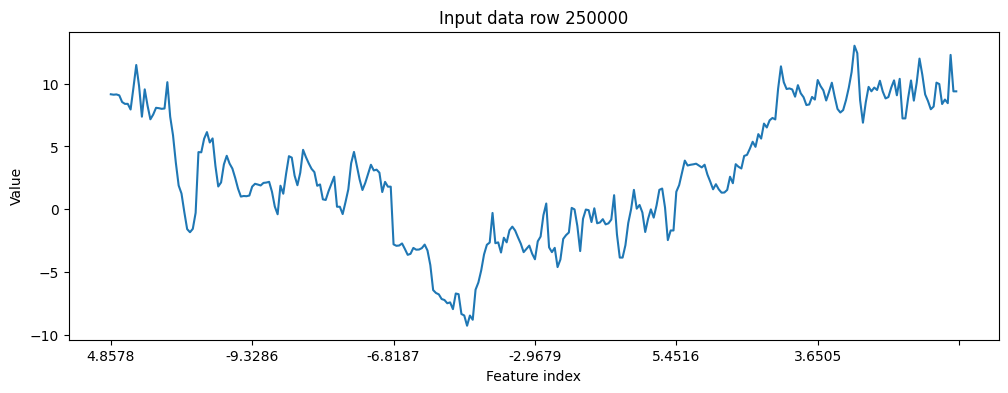

In [9]:
# Set the row index you want to plot
i = 250000  # change this

if not (0 <= i < len(input_df)):
    raise IndexError(f"i must be between 0 and {len(input_df) - 1}")

row = input_df.iloc[i]

ax = row.plot(figsize=(12, 4), title=f"Input data row {i}", legend=False)
ax.set_xlabel("Feature index")
ax.set_ylabel("Value")

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

# Features and target from existing notebook variables
X = input_df
y = output_df.iloc[:, 0].astype(int)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# MLP with two hidden layers: 100 and 50 neurons
mlp = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation="relu",
    solver="adam",
    max_iter=200,
    random_state=42,
    verbose=True
)

# Train
mlp.fit(X_train, y_train)

# Evaluate
y_pred = mlp.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Iteration 1, loss = 0.01184915
Iteration 2, loss = 0.00253922
Iteration 3, loss = 0.00205731
Iteration 4, loss = 0.00226171
Iteration 5, loss = 0.00114683
Iteration 6, loss = 0.00012585
Iteration 7, loss = 0.00008549
Iteration 8, loss = 0.00201947
Iteration 9, loss = 0.00038520
Iteration 10, loss = 0.00095198
Iteration 11, loss = 0.00009810
Iteration 12, loss = 0.00008996
Iteration 13, loss = 0.00008382
Iteration 14, loss = 0.00007705
Iteration 15, loss = 0.00353127
Iteration 16, loss = 0.00025050
Iteration 17, loss = 0.00119411
Training loss did not improve more than tol=0.000100 for 10 consecutive epochs. Stopping.
Accuracy: 0.999729752794925
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     34816
           1       1.00      1.00      1.00     35490

    accuracy                           1.00     70306
   macro avg       1.00      1.00      1.00     70306
weighted avg       1.00      1.00      1.00     70306



In [11]:
def split_into_thirds(df):
    n_cols = df.shape[1]
    cut1 = n_cols // 3
    cut2 = (2 * n_cols) // 3

    return {
        "first_third": df.iloc[:, :cut1].copy(),
        "second_third": df.iloc[:, cut1:cut2].copy(),
        "third_third": df.iloc[:, cut2:].copy(),
    }

# Split full input data
input_parts = split_into_thirds(input_df)

# Optional: split training data the same way
X_train_parts = split_into_thirds(X_train)

# Quick check
for name, part in input_parts.items():
    print(f"{name}: {part.shape}")

first_third: (351529, 100)
second_third: (351529, 100)
third_third: (351529, 100)


In [16]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, classification_report

# Build 3-step sequence input from the three parts (each part has ~100 features)
X_seq = np.stack(
    [
        input_parts["first_third"].to_numpy(dtype=np.float32),
        input_parts["second_third"].to_numpy(dtype=np.float32),
        input_parts["third_third"].to_numpy(dtype=np.float32),
    ],
    axis=1,  # (n_samples, 3, n_features_per_step)
)

y_seq = output_df.iloc[:, 0].to_numpy(dtype=np.float32)

# Train/test split
X_train_seq, X_test_seq, y_train_seq, y_test_seq = train_test_split(
    X_seq, y_seq, test_size=0.2, random_state=42, stratify=y_seq
)

X_train_t = torch.tensor(X_train_seq, dtype=torch.float32)
X_test_t = torch.tensor(X_test_seq, dtype=torch.float32)
y_train_t = torch.tensor(y_train_seq, dtype=torch.float32)
y_test_t = torch.tensor(y_test_seq, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=256, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=1024, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

class LSTMClassifier(nn.Module):
    def __init__(self, input_size, hidden_size=32, dense_size=16, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_size, dense_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(dense_size, 1)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        x = h_n[-1]
        x = self.dropout(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x).squeeze(1)

        return x



model = LSTMClassifier(input_size=X_train_t.shape[2]).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 10
for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch {epoch}/{epochs} - train loss: {epoch_loss:.4f}")

# Evaluation
model.eval()
all_logits = []
all_targets = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        logits = model(xb).cpu()
        all_logits.append(logits)
        all_targets.append(yb)

y_test_eval = torch.cat(all_targets).numpy().astype(int)
y_pred_prob = torch.sigmoid(torch.cat(all_logits)).numpy()
y_pred_lstm = (y_pred_prob >= 0.5).astype(int)

test_loss = criterion(torch.tensor(torch.cat(all_logits).numpy(), dtype=torch.float32), torch.tensor(y_test_eval, dtype=torch.float32)).item()
test_acc = accuracy_score(y_test_eval, y_pred_lstm)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")
print("Accuracy:", accuracy_score(y_test_eval, y_pred_lstm))
print(classification_report(y_test_eval, y_pred_lstm))


Using device: cpu
Epoch 1/10 - train loss: 0.0627
Epoch 2/10 - train loss: 0.0066
Epoch 3/10 - train loss: 0.0048
Epoch 4/10 - train loss: 0.0034
Epoch 5/10 - train loss: 0.0037
Epoch 6/10 - train loss: 0.0040
Epoch 7/10 - train loss: 0.0027
Epoch 8/10 - train loss: 0.0028
Epoch 9/10 - train loss: 0.0024
Epoch 10/10 - train loss: 0.0016
Test loss: 0.0017
Test accuracy: 0.9983
Accuracy: 0.9983216226211135
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     34816
           1       1.00      1.00      1.00     35490

    accuracy                           1.00     70306
   macro avg       1.00      1.00      1.00     70306
weighted avg       1.00      1.00      1.00     70306

